# Tasa de paro de los menores de 25 años

In [ ]:
# Parámetros de la gráfica
SLUG = "empleo"  # carpeta en research/temas/
GRAFICA_ID = "tasa-paro-juvenil"  # id de la gráfica (kebab-case) = nombre del notebook
TITULO = "Tasa de paro de los menores de 25 años"  # `titulo` de la gráfica en config.json
DESDE = 1976  # inicio de la ventana temporal (METODOLOGIA §2.3)
TIPO = "serie_temporal"  # serie_temporal | por_ccaa | solo_espana
VISTA = "lineas"  # `vista` de la gráfica en config.json: lineas | ultimo_anio | proyeccion | categorias
EJE_MAX = None  # `eje_max` de la gráfica en config.json; None = el que piden los datos
UNIDAD = "% de la población activa de 15 a 24 años"  # incluye deflactor/PPA si aplica (METODOLOGIA §2.4)
CSV_FORMATO = "es"  # CSV: "es" (separador ; y coma decimal, Excel en español) o "int" (, y punto)
CSV_DECIMALES = 1  # decimales del CSV (el JSON guarda el valor completo)
REFERENCIA = None  # línea horizontal de referencia (p. ej. 100 en un índice); None = sin línea
DIR_SALIDA = None  # solo tests; None = temas/<SLUG>/data/

## 1. Contexto

**Qué mide.** El porcentaje de la población activa de 15 a 24 años (los jóvenes que trabajan o buscan empleo) que está en paro: no tiene empleo, lo busca activamente y está disponible para trabajar, con la definición de la Organización Internacional del Trabajo (OIT).

**Cómo se lee.** Es la media anual de las tasas mensuales o trimestrales de las encuestas de población activa. Un valor de 25 significa que, de cada cien jóvenes activos, veinticinco están en paro. **No** es el porcentaje de todos los jóvenes: quien solo estudia no trabaja ni busca empleo y no está en el denominador. Por eso el notebook calcula también, para las notas, los parados de 15 a 24 años en porcentaje de toda la población de esa edad.

**Limitaciones.**
- Muchos jóvenes estudian y no son activos, así que el denominador es pequeño y la tasa sube mucho con pocos parados más.
- En EE. UU. el tramo es de 16 a 24 años.
- La tabla de Eurostat (`une_rt_a`) empieza en 2009 y el agregado de la OCDE en este dataflow, en 2005.

## 2. Descarga

- **España, EE. UU., Canadá y OCDE:** OCDE, Encuestas de población activa (`OECD.SDD.TPS,DSD_LFS@DF_IALFS_UNE_M`, versión 1.0): tasa de paro (`UNE_LF_M`), de 15 a 24 años (`Y15T24`), ambos sexos, frecuencia anual (`A`).
- **UE-27:** Eurostat `une_rt_a`: tasa de paro (`PC_ACT`), de 15 a 24 años (`Y15-24`), ambos sexos. El config nombra `age=Y_LT25`, que no devuelve datos en esta tabla; el tramo equivalente es `Y15-24` (anotado en `pending.md`).
- **Solo para las notas:** Eurostat `une_rt_a` para España (comparación con la OCDE) y los parados de 15 a 24 años en % de toda la población de esa edad (`PC_POP`), de España y la UE-27.

In [ ]:
import sys
from pathlib import Path

# Raíz del proyecto (la carpeta con global.json y lib/), buscando hacia arriba desde el directorio de ejecución
RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "global.json").exists()), None)
if RAIZ is None:
    raise FileNotFoundError(
        "No se encuentra global.json. Abre el notebook desde su carpeta (temas/<tema>/notebooks/) "
        "dentro del repositorio completo; consulta el README para instalar el entorno."
    )
sys.path.insert(0, str(RAIZ))

import pandas as pd

from lib import estilos
from lib.writer import construir_grafica_data, write_grafica_data

from lib import eurostat, oecd

AREAS_OCDE = {"ESP": "espana", "USA": "eeuu", "CAN": "canada", "OECD": "ocde"}
DATAFLOW_UNE = "OECD.SDD.TPS,DSD_LFS@DF_IALFS_UNE_M,1.0"
# Dimensiones: país . medida . unidad . transformación . ajuste . sexo . edad . actividad . frecuencia
CLAVE_UNE = "{AREA}.UNE_LF_M.PT_LF_SUB._Z.N._T.Y15T24._Z.A"
FILTROS_EU = {"age": "Y15-24", "sex": "T", "unit": "PC_ACT"}

oc, fuentes_oc = oecd.get(DATAFLOW_UNE, CLAVE_UNE, areas=AREAS_OCDE, desde=DESDE)
eu, fuentes_eu = eurostat.get("une_rt_a", FILTROS_EU, geos={"EU27_2020": "ue27"}, desde=DESDE)
# Solo para las notas
eu_esp, _ = eurostat.get("une_rt_a", FILTROS_EU, geos={"ES": "espana"}, desde=DESDE)
ratio, _ = eurostat.get("une_rt_a", {**FILTROS_EU, "unit": "PC_POP"}, geos={"ES": "espana", "EU27_2020": "ue27"}, desde=DESDE)
print(oc.groupby("serie")["periodo"].agg(["min", "max"]))
print(eu.groupby("serie")["periodo"].agg(["min", "max"]))

         min   max
serie             
canada  1976  2025
eeuu    1976  2024
espana  1987  2025
ocde    2005  2024
        min   max
serie            
ue27   2009  2025


## 3. Transformación

1. Las series se usan tal como las publican las fuentes: son tasas, sin deflactor ni conversión. La OCDE no publica la UE-27 en este dataflow y se usa Eurostat.
2. **Comparación de España** en la OCDE y en Eurostat, para las notas.
3. **Parados en % de toda la población de 15 a 24 años** (Eurostat, `PC_POP`), para explicar en las notas la diferencia con la tasa de paro.

In [ ]:
def es(v, d=1):
    return estilos.formato_es(v, d)


serie = lambda d, s: d[d["serie"] == s].set_index("periodo")["valor"].dropna()  # noqa: E731


def comparar(a, b):
    """Años comunes de dos series y diferencia absoluta entre ellas, en puntos."""
    comunes = sorted(set(a.index) & set(b.index))
    return comunes, (a[comunes] - b[comunes]).abs()


def nota_comparacion(texto, a, b, d=2):
    comunes, dif = comparar(a, b)
    return (f"{texto}: en los {len(comunes)} años comunes ({comunes[0]}-{comunes[-1]}), la diferencia máxima es de "
            f"{es(dif.max(), d)} puntos, en {int(dif.idxmax())}.")


df = pd.concat([oc, eu], ignore_index=True)
fuentes = [*fuentes_oc, *fuentes_eu]
assert df["valor"].between(0, 100).all(), "porcentaje fuera de rango"

ULTIMO = int(ratio["periodo"].max())
r_esp, r_ue = serie(ratio, "espana")[ULTIMO], serie(ratio, "ue27")[ULTIMO]
t_esp, t_ue = serie(eu_esp, "espana")[ULTIMO], serie(eu, "ue27")[ULTIMO]
NOTAS = [
    "España, EE. UU., Canadá y OCDE: OCDE, Encuestas de población activa (DSD_LFS@DF_IALFS_UNE_M): tasa de paro de "
    "15 a 24 años, media anual, definición armonizada de la OIT. En EE. UU. el tramo es de 16 a 24 años.",
    "UE-27: Eurostat (une_rt_a), de 15 a 24 años, ambos sexos, agregado de composición actual (EU27_2020).",
    "El denominador es la población activa joven (quienes trabajan o buscan empleo), no todos los jóvenes: quienes solo "
    f"estudian no cuentan. En {ULTIMO}, los parados de 15 a 24 años eran el {es(r_esp)} % de toda la población de esa "
    f"edad en España y el {es(r_ue)} % en la UE-27, con una tasa de paro del {es(t_esp)} % y el {es(t_ue)} % "
    "(Eurostat, une_rt_a, PC_POP y PC_ACT).",
    nota_comparacion("Comparación de España en la OCDE y en Eurostat", serie(oc, "espana"), serie(eu_esp, "espana")),
    "Rupturas de serie de la EPA: cambio de la definición de parado en 2001 y renovación del cuestionario y de la "
    "metodología de la encuesta en 2005; la serie de la OCDE las enlaza.",
]
for n in NOTAS:
    print("-", n)

- España, EE. UU., Canadá y OCDE: OCDE, Encuestas de población activa (DSD_LFS@DF_IALFS_UNE_M): tasa de paro de 15 a 24 años, media anual, definición armonizada de la OIT. En EE. UU. el tramo es de 16 a 24 años.
- UE-27: Eurostat (une_rt_a), de 15 a 24 años, ambos sexos, agregado de composición actual (EU27_2020).
- El denominador es la población activa joven (quienes trabajan o buscan empleo), no todos los jóvenes: quienes solo estudian no cuentan. En 2025, los parados de 15 a 24 años eran el 8,4 % de toda la población de esa edad en España y el 6,2 % en la UE-27, con una tasa de paro del 24,9 % y el 15,2 % (Eurostat, une_rt_a, PC_POP y PC_ACT).
- Comparación de España en la OCDE y en Eurostat: en los 17 años comunes (2009-2025), la diferencia máxima es de 0,14 puntos, en 2021.
- Rupturas de serie de la EPA: cambio de la definición de parado en 2001 y renovación del cuestionario y de la metodología de la encuesta en 2005; la serie de la OCDE las enlaza.


## 4. Visualización

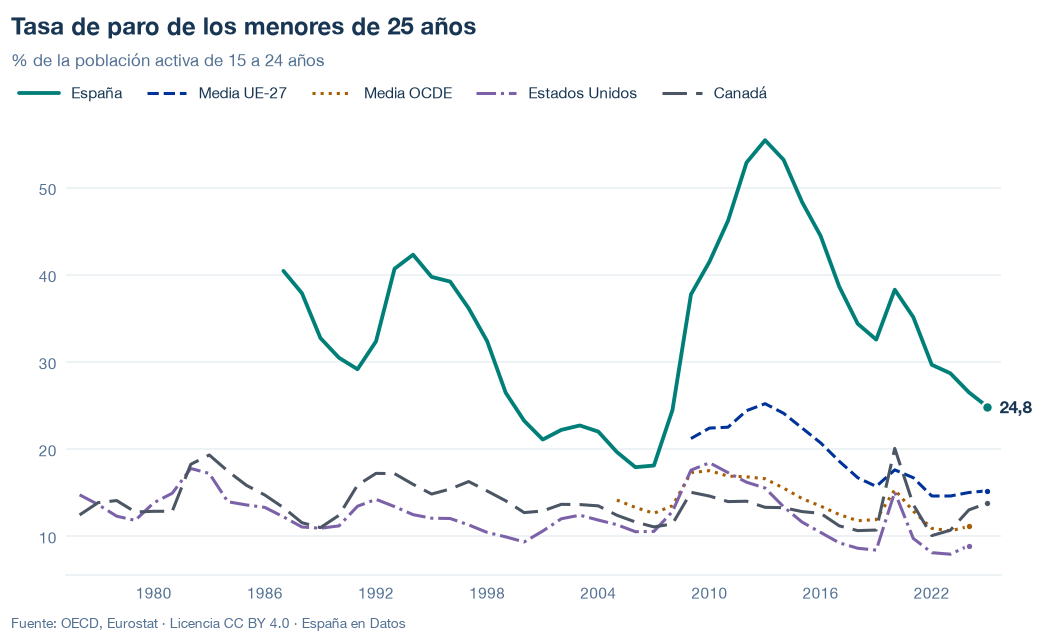

In [ ]:
datos = construir_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, referencia=REFERENCIA,
)
fig = estilos.figura(datos, titulo=TITULO, vista=VISTA, eje_max=EJE_MAX)
estilos.mostrar(fig)

## 5. Exportación

Escribe `data/<id>.json` (validado contra el esquema) y `data/<id>.csv`, el mismo CSV que se descarga en la web.

In [ ]:
salida = Path(DIR_SALIDA) if DIR_SALIDA else RAIZ / "temas" / SLUG / "data"
ruta = write_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, referencia=REFERENCIA,
    path=salida / f"{GRAFICA_ID}.json", csv_formato=CSV_FORMATO, csv_decimales=CSV_DECIMALES,
)
print(f"escrito: data/{ruta.name} y data/{ruta.stem}.csv")  # sin rutas locales en las salidas publicadas

escrito: data/tasa-paro-juvenil.json y data/tasa-paro-juvenil.csv


## 6. Fuentes, notas y licencia

- OCDE, Encuestas de población activa: `OECD.SDD.TPS,DSD_LFS@DF_IALFS_UNE_M,1.0` (`UNE_LF_M`, `PT_LF_SUB`, `N`, `_T`, `Y15T24`, `A`).
- Eurostat, `une_rt_a` (`Y15-24`, `T`, `PC_ACT`; `PC_POP` solo para las notas).

La fecha de consulta de cada serie está en `fuentes` del JSON.

**Licencia:** datos, gráficos y textos CC BY 4.0; código MIT. Cita a España en Datos.